# Mini-Project 1 — UBOS District Population Forecaster

**Scenario.** A district planning unit wants 5-year population forecasts to plan primary-school classrooms.

**Data provenance (read first).**

| District | Source | Nature |
|---|---|---|
| Kampala, Wakiso, Gulu | Assignment PDF | **Illustrative (synthetic)** — not official UBOS figures |
| Arua City, Kasese | UBOS (2022) *Revised Subcounty Population Projections 2015 to 2030 for 146 Districts*, district total rows, converted from persons to thousands | **UBOS projections** based on the 2014 census — modelled estimates, not annual head-counts |

All populations are in **thousands**. The two groups must not be compared as if they were the same kind of data: the illustrative series are synthetic, and the UBOS series are smooth model outputs.

All reusable logic lives in `src/population.py` (tested in `tests/test_population.py`); this notebook only calls it, presents results and interprets them.

In [1]:
# Make the project root importable (the notebook runs from notebooks/).
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import statistics
import numpy as np
import matplotlib.pyplot as plt

from src.population import (
    DistrictPopulation, load_ubos_district,
    LinearTrendForecaster, CAGRForecaster, FibonacciRatioForecaster,
    evaluate, select_best, additional_classrooms, bootstrap_intervals,
)

UBOS_FILE = PROJECT_ROOT / "data" / "Revised_Subcounty_population_2015_2030_146_Districts.xlsx"
SEED = 2026            # one seed for every random step in this notebook
LAST_TRAIN_YEAR = 2021 # train 2015-2021, test 2022-2024
HORIZON = 5            # forecast 2025-2029
np.set_printoptions(precision=2, suppress=True)

## 1. Data and the `DistrictPopulation` class (Task 1)

`DistrictPopulation` stores years and populations as NumPy arrays and validates them on construction (non-empty, equal lengths, finite, non-negative, strictly increasing whole-number years). It implements `__repr__` and `__len__`. The two UBOS districts are read straight from the official workbook by `load_ubos_district`.

In [2]:
YEARS = list(range(2015, 2025))
ILLUSTRATIVE = "Illustrative (assignment PDF)"

districts = [
    DistrictPopulation("Kampala", YEARS, [1200, 1250, 1300, 1350, 1420, 1500, 1580, 1650, 1720, 1800], ILLUSTRATIVE),
    DistrictPopulation("Wakiso",  YEARS, [ 950, 1000, 1070, 1150, 1220, 1300, 1390, 1480, 1570, 1670], ILLUSTRATIVE),
    DistrictPopulation("Gulu",    YEARS, [ 320,  330,  345,  360,  375,  390,  410,  430,  455,  480], ILLUSTRATIVE),
    load_ubos_district(UBOS_FILE, "Arua City"),
    load_ubos_district(UBOS_FILE, "Kasese"),
]

for d in districts:
    print(repr(d), "| len =", len(d))
print()
for d in districts[3:]:
    print(f"{d.name:<10}", d.populations)

DistrictPopulation(name='Kampala', years=2015–2024, n=10, source='Illustrative (assignment PDF)') | len = 10
DistrictPopulation(name='Wakiso', years=2015–2024, n=10, source='Illustrative (assignment PDF)') | len = 10
DistrictPopulation(name='Gulu', years=2015–2024, n=10, source='Illustrative (assignment PDF)') | len = 10
DistrictPopulation(name='Arua City', years=2015–2024, n=10, source='UBOS (2022) Revised Subcounty Population Projections 2015 to 2030 for 146 Districts (projections, not census counts)') | len = 10
DistrictPopulation(name='Kasese', years=2015–2024, n=10, source='UBOS (2022) Revised Subcounty Population Projections 2015 to 2030 for 146 Districts (projections, not census counts)') | len = 10

Arua City  [316.  324.6 334.  343.1 352.3 361.4 371.  380.1 389.5 399.4]
Kasese     [707.6 724.5 741.6 758.9 776.1 793.2 810.4 827.2 843.9 860.3]


In [3]:
# Validation in action: invalid input raises a clear ValueError.
for bad in ({"years": [2015, 2016], "pops": [100]},          # unequal lengths
            {"years": [2015, 2016], "pops": [100, -1]}):     # negative value
    try:
        DistrictPopulation("Bad", bad["years"], bad["pops"], "demo")
    except ValueError as err:
        print("Rejected:", err)

Rejected: years (2) and populations (1) must have equal length.
Rejected: populations must not be negative.


## 2. Descriptive statistics two ways (Task 2)

**Why `statistics.variance` and `np.var` differ.** `statistics.variance` is the **sample** variance: it divides the sum of squared deviations by *n − 1*. `np.var` defaults to the **population** variance: it divides by *n*. The *n − 1* (Bessel's correction) compensates for measuring spread around the sample mean, which is always closer to the data than the unknown true mean, so dividing by *n* would systematically underestimate the variance of the process that generated the data.

**`ddof`** ("delta degrees of freedom") sets NumPy's divisor to *n − ddof*: `ddof=0` (default) gives the population variance and `ddof=1` the sample variance. So `statistics.variance(x) == np.var(x, ddof=1)` and `statistics.pvariance(x) == np.var(x)`. With *n* = 10 the population variance is always exactly 0.9 × the sample variance.

Here the ten values are a time series with a strong trend, not a random sample, so the "variance" mostly measures how much the population grew over the decade, not random variability. That matters again in Section 6.

In [4]:
header = f"{'District':<10} {'Method':<11} {'Mean':>9} {'Median':>9} {'Var (n-1)':>11} {'Var (n)':>11} {'SD (n-1)':>9}"
print(header); print("-" * len(header))
for d in districts:
    s = d.summary()
    for method in ("statistics", "numpy"):
        m = s[method]
        print(f"{d.name:<10} {method:<11} {m['mean']:9.1f} {m['median']:9.1f} "
              f"{m['sample_variance']:11.1f} {m['population_variance']:11.1f} {m['sample_std']:9.2f}")

k = districts[0].populations
print("\nKampala check:")
print("  statistics.variance =", round(statistics.variance(k.tolist()), 2))
print("  np.var (ddof=0)     =", round(float(np.var(k)), 2))
print("  np.var (ddof=1)     =", round(float(np.var(k, ddof=1)), 2))
print("  ratio pop/sample    =", round(float(np.var(k) / np.var(k, ddof=1)), 4), "= (n-1)/n = 9/10")

District   Method           Mean    Median   Var (n-1)     Var (n)  SD (n-1)
----------------------------------------------------------------------------
Kampala    statistics     1477.0    1460.0     42601.1     38341.0    206.40
Kampala    numpy          1477.0    1460.0     42601.1     38341.0    206.40
Wakiso     statistics     1280.0    1260.0     60066.7     54060.0    245.09
Wakiso     numpy          1280.0    1260.0     60066.7     54060.0    245.09
Gulu       statistics      389.5     382.5      2885.8      2597.2     53.72
Gulu       numpy           389.5     382.5      2885.8      2597.2     53.72
Arua City  statistics      357.1     356.9       786.4       707.8     28.04
Arua City  numpy           357.1     356.9       786.4       707.8     28.04
Kasese     statistics      784.4     784.7      2658.2      2392.4     51.56
Kasese     numpy           784.4     784.7      2658.2      2392.4     51.56

Kampala check:
  statistics.variance = 42601.11
  np.var (ddof=0)     = 383

## 3. Growth rates and CAGR (Task 3)

Year-on-year growth is $g_t = P_t / P_{t-1} - 1$, giving 9 rates from 10 years. The compound annual growth rate is

$$\text{CAGR} = \left(\frac{P_{2024}}{P_{2015}}\right)^{1/9} - 1,$$

using **9 intervals**, not 10.

In [5]:
print(f"{'District':<10}", " ".join(f"{y:>6}" for y in YEARS[1:]), f"{'CAGR':>8}")
for d in districts:
    rates = d.growth_rates() * 100
    print(f"{d.name:<10}", " ".join(f"{r:6.2f}" for r in rates), f"{d.cagr()*100:7.2f}%")

ranked = sorted(districts, key=lambda d: d.cagr(), reverse=True)
print("\nRanking by CAGR:", " > ".join(f"{d.name} ({d.cagr()*100:.2f}%)" for d in ranked))
print("Kampala and Gulu ratio 2024/2015:", districts[0].populations[-1] / districts[0].populations[0],
      "and", districts[2].populations[-1] / districts[2].populations[0])

District     2016   2017   2018   2019   2020   2021   2022   2023   2024     CAGR
Kampala      4.17   4.00   3.85   5.19   5.63   5.33   4.43   4.24   4.65    4.61%
Wakiso       5.26   7.00   7.48   6.09   6.56   6.92   6.47   6.08   6.37    6.47%
Gulu         3.12   4.55   4.35   4.17   4.00   5.13   4.88   5.81   5.49    4.61%
Arua City    2.72   2.90   2.72   2.68   2.58   2.66   2.45   2.47   2.54    2.64%
Kasese       2.39   2.36   2.33   2.27   2.20   2.17   2.07   2.02   1.94    2.19%

Ranking by CAGR: Wakiso (6.47%) > Kampala (4.61%) > Gulu (4.61%) > Arua City (2.64%) > Kasese (2.19%)
Kampala and Gulu ratio 2024/2015: 1.5 and 1.5


**Interpretation.** **Wakiso grows fastest in relative terms** (≈6.5 % a year). Kampala and Gulu have *identical* CAGRs (≈4.6 %) because both series grow by exactly a factor of 1.5, even though Kampala adds 600 thousand people and Gulu only 160 thousand: relative and absolute growth answer different planning questions. The year-on-year rates also show shape: Gulu's rates rise over time (accelerating), while the UBOS series' rates fall slowly (decelerating). A single constant-rate model can capture neither, which matters for model choice below.

## 4. Forecasting models (Task 4)

All three models inherit from the abstract `Forecaster` base class, which exposes `fit(years, values)` and `predict(horizon)` and does all input validation once.

* **`LinearTrendForecaster`** — least-squares straight line via `np.polyfit(t, y, 1)` with centred years $t = \text{year} - 2015$ (better numerical conditioning, identical predictions).
* **`CAGRForecaster`** — constant percentage growth: $\hat P_{T+h} = P_T(1+g)^h$, with $g$ the training-period CAGR. Because $g$ uses only the two endpoints, the fitted curve passes exactly through the first and last training points.
* **`FibonacciRatioForecaster`** — the previous cohort's method: multiply the last value by successive Fibonacci ratios $r_k = F_{k+1}/F_k$. **Stated assumption:** the ratios compound and start at $r_1 = F_2/F_1 = 1$. The model learns nothing from the data except the last value, so it has no in-sample fit.

In [6]:
fib_model = FibonacciRatioForecaster()
print("Fibonacci ratios used for horizons 1-8:", fib_model.ratios(8))
print("Cumulative multiplier after h years:  ", np.cumprod(fib_model.ratios(8)))
print("Limit (golden ratio):", (1 + 5 ** 0.5) / 2)

Fibonacci ratios used for horizons 1-8: [1.   2.   1.5  1.67 1.6  1.62 1.62 1.62]
Cumulative multiplier after h years:   [ 1.  2.  3.  5.  8. 13. 21. 34.]
Limit (golden ratio): 1.618033988749895


## 5. Validation: train 2015–2021, test 2022–2024 (Task 5)

Each model is fitted on 2015–2021 (7 points) and asked to forecast 2022–2024 (horizon 3).

* **MAE** = mean |error| (thousands) — the typical miss.
* **RMSE** = √mean(error²) (thousands) — penalises large misses more heavily.
* **MAPE** = 100 × mean |error / actual| (%) — scale-free, so districts can be compared.

**Selection rule:** lowest RMSE, MAPE as tie-break. For classroom planning, one large miss means a real shortfall, so the metric that weights large errors more heavily is the appropriate one.

In [7]:
MODEL_CLASSES = {"LinearTrend": LinearTrendForecaster, "CAGR": CAGRForecaster}
results, best_model = {}, {}

for d in districts:
    rows = evaluate(d, [LinearTrendForecaster(), CAGRForecaster(), FibonacciRatioForecaster()], LAST_TRAIN_YEAR)
    results[d.name] = rows
    best_model[d.name] = select_best(rows)
    print(f"\n{d.name} ({'illustrative' if d.source == ILLUSTRATIVE else 'UBOS projection'}) - test 2022-2024")
    print(f"  {'Model':<15} {'MAE':>9} {'RMSE':>9} {'MAPE %':>8}   predictions")
    for r in rows:
        flag = "  <- selected" if r["model"] == best_model[d.name] else ""
        print(f"  {r['model']:<15} {r['MAE']:9.2f} {r['RMSE']:9.2f} {r['MAPE']:8.2f}   {np.round(r['predictions'], 1)}{flag}")


Kampala (illustrative) - test 2022-2024
  Model                 MAE      RMSE   MAPE %   predictions
  LinearTrend         37.62     38.97     2.17   [1622.9 1685.7 1748.6]
  CAGR                 9.62     10.39     0.55   [1654.1 1731.7 1813. ]  <- selected
  FibonacciRatio    1483.33   1890.51    83.77   [1580. 3160. 4740.]

Wakiso (illustrative) - test 2022-2024
  Model                 MAE      RMSE   MAPE %   predictions
  LinearTrend         49.40     52.37     3.09   [1450.  1523.9 1597.9]
  CAGR                 6.80      8.05     0.42   [1481.  1578.  1681.4]  <- selected
  FibonacciRatio    1266.67   1604.39    77.62   [1390. 2780. 4170.]

Gulu (illustrative) - test 2022-2024
  Model                 MAE      RMSE   MAPE %   predictions
  LinearTrend         18.57     20.29     4.01   [421.4 436.4 451.4]
  CAGR                 9.44     10.87     2.02   [427.3 445.3 464.1]  <- selected
  FibonacciRatio     378.33    481.71    80.37   [ 410.  820. 1230.]

Arua City (UBOS projectio

In [8]:
# Second-method check of one table entry, by hand: Kampala, CAGR model.
train, test = districts[0].split(LAST_TRAIN_YEAR)
g = (train.populations[-1] / train.populations[0]) ** (1 / 6) - 1   # 6 intervals in 2015-2021
hand = train.populations[-1] * (1 + g) ** np.arange(1, 4)
hand_rmse = np.sqrt(np.mean((test.populations - hand) ** 2))
module_rmse = next(r["RMSE"] for r in results["Kampala"] if r["model"] == "CAGR")
print(f"g = {g:.5f}; hand forecasts = {np.round(hand, 2)}")
print(f"hand RMSE = {hand_rmse:.4f} | module RMSE = {module_rmse:.4f} | match: {np.isclose(hand_rmse, module_rmse)}")

g = 0.04692; hand forecasts = [1654.13 1731.74 1812.99]
hand RMSE = 10.3851 | module RMSE = 10.3851 | match: True


**Interpretation.** The Fibonacci model is worst everywhere by two orders of magnitude (MAPE ≈ 78–92 %), because it triples the 2021 value within three years. **CAGR wins for the three illustrative districts** and **the linear trend wins for the two UBOS districts.** This matches the growth-rate shapes in Section 3: the illustrative series grow at a roughly constant or rising *percentage*, whereas UBOS's projected growth rates fall slowly, so adding a roughly constant *number* of people each year fits better. Note the scale of the UBOS errors (≈1 thousand people): UBOS's own projections are smooth by construction, so these small errors partly reflect that we are forecasting another model's output, not real head-counts. With only three test years, these rankings are indicative rather than conclusive.

## 6. Forecast 2025–2029 and variance comparison (Task 6)

As stated in the plan, the selected model is **refitted on all ten years (2015–2024)** before forecasting, so the forecast uses the most recent information.

In [9]:
final_models, forecasts = {}, {}
FORECAST_YEARS = np.arange(2025, 2025 + HORIZON)

print(f"{'District':<10} {'Model':<12}", " ".join(f"{y:>8}" for y in FORECAST_YEARS))
for d in districts:
    model = MODEL_CLASSES[best_model[d.name]]().fit(d.years, d.populations)
    final_models[d.name] = model
    forecasts[d.name] = model.predict(HORIZON)
    print(f"{d.name:<10} {model.name:<12}", " ".join(f"{v:8.1f}" for v in forecasts[d.name]))

District   Model            2025     2026     2027     2028     2029
Kampala    CAGR           1882.9   1969.7   2060.5   2155.4   2254.8
Wakiso     CAGR           1778.0   1893.0   2015.5   2145.9   2284.7
Gulu       CAGR            502.1    525.3    549.5    574.8    601.3
Arua City  LinearTrend     408.1    417.3    426.6    435.9    445.1
Kasese     LinearTrend     878.0    895.1    912.1    929.1    946.1


In [10]:
print(f"{'District':<10} {'Var actual':>11} {'Var forecast':>13} {'Var of yearly change: actual':>30} {'forecast':>9}")
for d in districts:
    f = forecasts[d.name]
    print(f"{d.name:<10} {statistics.variance(d.populations.tolist()):11.1f} {statistics.variance(f.tolist()):13.1f} "
          f"{statistics.variance(np.diff(d.populations).tolist()):30.2f} {statistics.variance(np.diff(f).tolist()):9.2f}")

# Why the raw variances differ even for a perfect straight line: n equally spaced points on a line
# with slope b have variance b^2 * n(n+1)/12 (sample variance), so 10 points vs 5 points differ by span alone.
b = final_models["Kasese"].slope_
print(f"\nKasese slope = {b:.2f} thousand/yr -> theoretical line variance: 10 pts {b**2*10*11/12:.1f}, 5 pts {b**2*5*6/12:.1f}")

District    Var actual  Var forecast   Var of yearly change: actual  forecast
Kampala        42601.1       21607.7                         175.00     29.21
Wakiso         60066.7       40131.4                         225.00    104.90
Gulu            2885.8        1536.5                          25.69      2.08
Arua City        786.4         214.5                           0.13      0.00
Kasese          2658.2         724.9                           0.09      0.00

Kasese slope = 17.03 thousand/yr -> theoretical line variance: 10 pts 2658.1, 5 pts 724.9


**What the variance difference tells us.** The forecast series always has a much smaller variance than the actual series, but most of that gap is arithmetic, not insight: both series are dominated by trend, and a trend over **5 years** spreads less than a trend over **10 years**. For a perfect straight line the variance grows with the square of the span (the Kasese check above reproduces the observed values almost exactly).

The more informative comparison is the variance of the **year-to-year changes**. For the actual data it reflects genuine wobbles in growth. For the forecasts it is exactly zero under the linear model (the same increment every year), and under the CAGR model it comes only from the smooth, steadily growing increments of compounding — Wakiso's forecast value of ≈105 is pure compounding, not noise. In other words, **point forecasts contain none of the year-to-year noise seen in real data**, so their narrow spread must not be read as certainty. This is the motivation for the prediction intervals in Section 9.

## 7. Actual, fitted and forecast values (Task 7)

Each panel shows: actual values; the selected model refitted on 2015–2024 and its 2025–2029 forecast with the 95 % bootstrap interval (Section 9); and the validation-stage test predictions (2022–2024) of all three models, trained on 2015–2021 only. The Fibonacci model has no in-sample fit, so only its test predictions are shown; where they run off the axis, the panel states the 2024 value instead of letting it flatten the other lines.

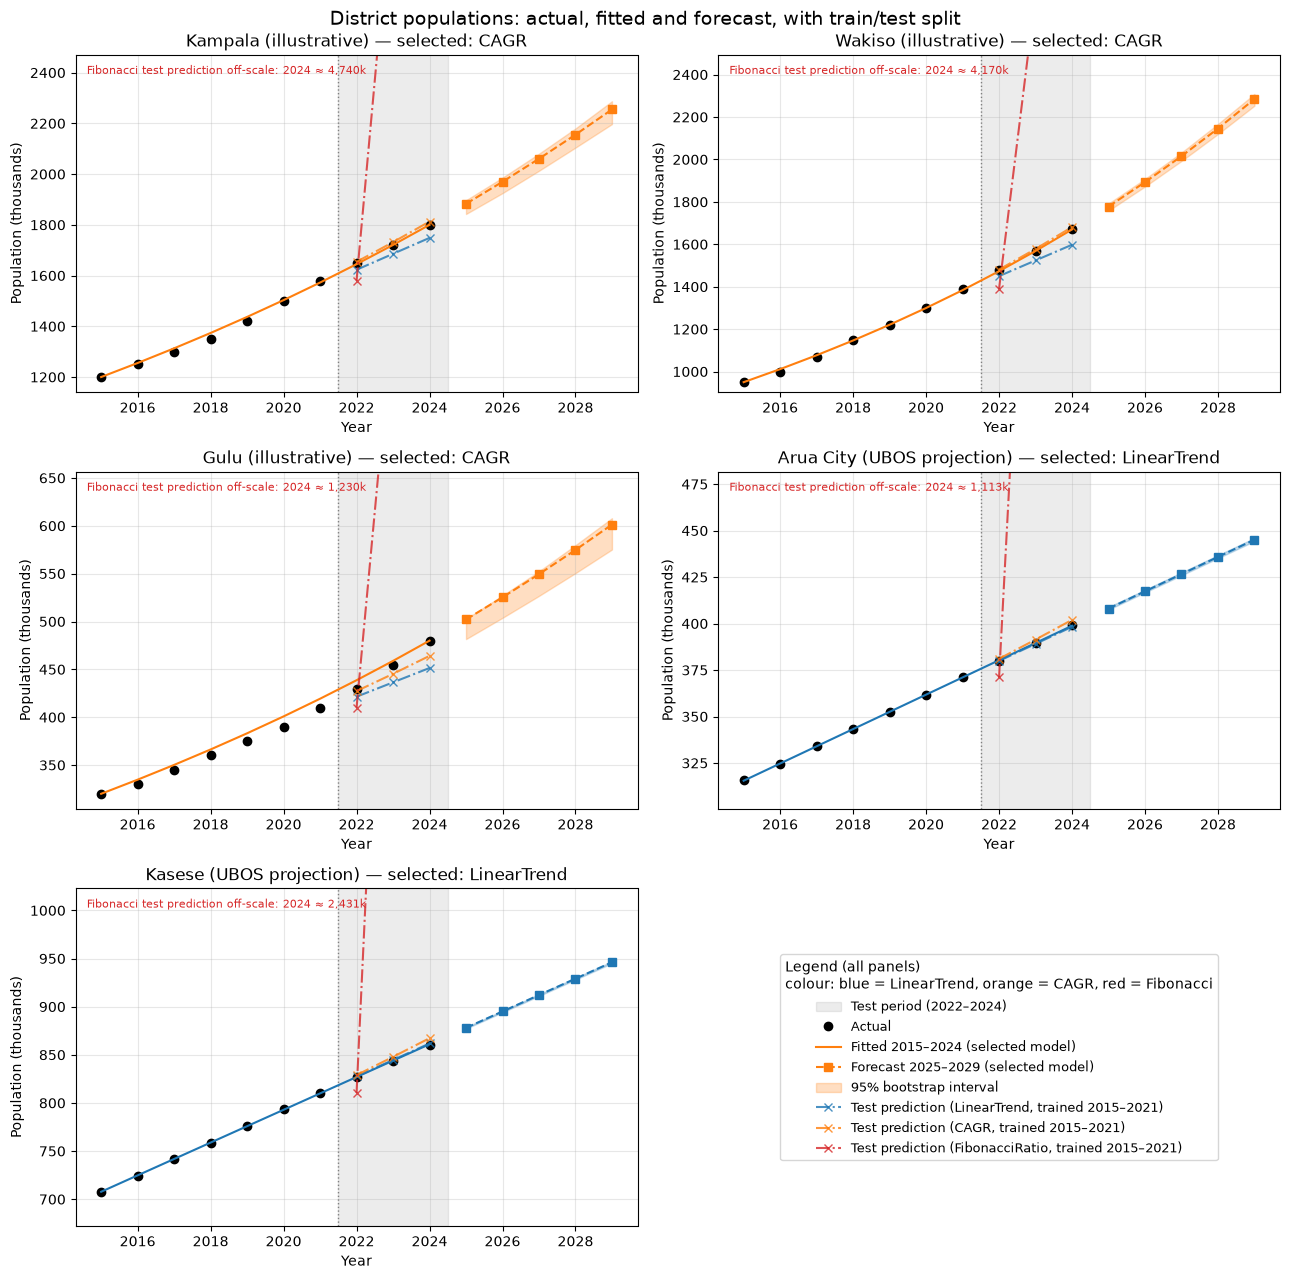

In [11]:
intervals = {}
for d in districts:
    intervals[d.name] = bootstrap_intervals(MODEL_CLASSES[best_model[d.name]], d.years, d.populations,
                                            HORIZON, n_boot=1000, level=0.95, seed=SEED)

colors = {"LinearTrend": "tab:blue", "CAGR": "tab:orange", "FibonacciRatio": "tab:red"}
fig, axes = plt.subplots(3, 2, figsize=(13, 13))
axes = axes.ravel()
test_years = np.arange(LAST_TRAIN_YEAR + 1, 2025)

for ax, d in zip(axes, districts):
    model = final_models[d.name]
    point, lower, upper = intervals[d.name]
    ax.axvspan(LAST_TRAIN_YEAR + 0.5, 2024.5, color="grey", alpha=0.15, label="Test period (2022–2024)")
    ax.axvline(LAST_TRAIN_YEAR + 0.5, color="grey", linestyle=":", linewidth=1)
    ax.plot(d.years, d.populations, "ko", label="Actual")
    ax.plot(d.years, model.fitted_values(), "-", color=colors[model.name], label="Fitted 2015–2024 (selected model)")
    ax.plot(FORECAST_YEARS, point, "--", color=colors[model.name], marker="s", label="Forecast 2025–2029 (selected model)")
    ax.fill_between(FORECAST_YEARS, lower, upper, color=colors[model.name], alpha=0.25, label="95% bootstrap interval")

    top = max(d.populations.max(), upper.max()) * 1.08
    bottom = d.populations.min() * 0.95
    for r in results[d.name]:
        ax.plot(test_years, r["predictions"], linestyle="-.", marker="x", color=colors[r["model"]], alpha=0.8,
                label=f"Test prediction ({r['model']}, trained 2015–2021)")
        if r["predictions"].max() > top:
            ax.text(0.02, 0.97, f"Fibonacci test prediction off-scale: 2024 ≈ {r['predictions'][-1]:,.0f}k",
                    transform=ax.transAxes, va="top", fontsize=8, color=colors[r["model"]])
    ax.set_ylim(bottom, top)
    kind = "illustrative" if d.source == ILLUSTRATIVE else "UBOS projection"
    ax.set_title(f"{d.name} ({kind}) — selected: {model.name}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Population (thousands)")
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
seen = dict(zip(labels, handles))
axes[-1].axis("off")
axes[-1].legend(seen.values(), seen.keys(), loc="center", fontsize=9, title="Legend (all panels)\ncolour: blue = LinearTrend, orange = CAGR, red = Fibonacci")
fig.suptitle("District populations: actual, fitted and forecast, with train/test split", fontsize=14)
fig.tight_layout()
plt.show()

**Reading the figure.** In every panel the selected model's fitted line tracks the actual points closely and the forecast continues the recent trend smoothly. The test-period predictions show *why* each model was chosen: for Wakiso and Gulu the linear prediction visibly falls below the actual curve because the series accelerate, while for Arua City and Kasese the CAGR prediction overshoots because growth is decelerating. Fibonacci is off-scale in every panel.

## 8. Planning output: additional classrooms by 2029 (Task 8)

Assumptions from the assignment: 18 % of the population is of primary-school age and a classroom holds 53 pupils. **Stated assumption:** current (2024) classroom capacity exactly meets 2024 need, so only the *growth* from 2024 to 2029 requires new classrooms. Classrooms are rounded **up** (a fraction of a classroom still needs a room), and a declining population would give 0, not a negative number.

$$\text{Additional classrooms} = \left\lceil \frac{0.18 \times (P_{2029} - P_{2024}) \times 1000}{53} \right\rceil$$

In [12]:
print(f"{'District':<10} {'P2024 (k)':>10} {'P2029 (k)':>10} {'Extra pupils':>13} {'Classrooms':>11} {'95% range':>14}")
for d in districts:
    p_now, p_2029 = d.populations[-1], forecasts[d.name][-1]
    _, lower, upper = intervals[d.name]
    rooms = additional_classrooms(p_now, p_2029)
    rooms_lo, rooms_hi = additional_classrooms(p_now, lower[-1]), additional_classrooms(p_now, upper[-1])
    print(f"{d.name:<10} {p_now:10.1f} {p_2029:10.1f} {0.18 * (p_2029 - p_now) * 1000:13,.0f} {rooms:11,d} "
          f"{rooms_lo:>6,d}–{rooms_hi:<6,d}")

# Hand check (Kampala): 0.18 x (2029 forecast - 1800) x 1000 / 53, rounded up
k29 = forecasts["Kampala"][-1]
print(f"\nHand check Kampala: 0.18 x ({k29:.2f} - 1800) x 1000 / 53 = {0.18 * (k29 - 1800) * 1000 / 53:.2f} -> round up")

District    P2024 (k)  P2029 (k)  Extra pupils  Classrooms      95% range
Kampala        1800.0     2254.8        81,857       1,545  1,349–1,656 
Wakiso         1670.0     2284.7       110,641       2,088  1,982–2,170 
Gulu            480.0      601.3        21,829         412    324–435   
Arua City       399.4      445.1         8,231         156    153–159   
Kasese          860.3      946.1        15,451         292    289–295   

Hand check Kampala: 0.18 x (2254.76 - 1800) x 1000 / 53 = 1544.48 -> round up


**Interpretation.** Wakiso needs the most new classrooms (≈2,100) despite starting below Kampala, because it grows fastest; Kampala needs ≈1,550. The figures are best read as **minimum** requirements, since they assume today's capacity is adequate and that 18 % / 53 pupils stay fixed — any existing overcrowding or backlog in 2024 is not included. The 95 % ranges translate forecast uncertainty into a planning range, though they are likely too narrow (see Section 9).

## 9. Extension

### 9a. Residual-bootstrap 95 % prediction intervals

Method (`bootstrap_intervals`, 1,000 resamples, seed fixed): fit the selected model to all ten years; take residuals *actual − fitted*; for each resample, add residuals drawn with replacement to the fitted values, refit a fresh model, forecast, and add one resampled residual per future year for observation noise. The 2.5th and 97.5th percentiles of the 1,000 simulated paths form the interval, shaded in the figure above.

In [13]:
print(f"{'District':<10}", " ".join(f"{y:>17}" for y in FORECAST_YEARS), "   (lower–upper, thousands)")
for d in districts:
    point, lower, upper = intervals[d.name]
    print(f"{d.name:<10}", " ".join(f"{lo:8.1f}–{hi:<8.1f}" for lo, hi in zip(lower, upper)))

print("\nResiduals of the selected models (thousands):")
for d in districts:
    print(f"  {d.name:<10}", np.round(d.populations - final_models[d.name].fitted_values(), 1))

District                2025              2026              2027              2028              2029    (lower–upper, thousands)
Kampala      1842.6–1896.9     1925.0–1986.1     2013.1–2080.5     2104.4–2180.0     2197.1–2287.4  
Wakiso       1758.4–1792.2     1872.4–1908.3     1992.7–2032.6     2119.9–2167.4     2253.5–2308.8  
Gulu          481.6–502.8       503.8–527.2       526.7–552.5       550.5–579.8       575.2–608.0   
Arua City     407.5–408.9       416.8–418.2       426.0–427.5       435.2–436.8       444.4–446.1   
Kasese        877.2–878.7       894.1–895.8       911.1–912.8       928.1–930.0       945.1–947.0   

Residuals of the selected models (thousands):
  Kampala    [  0.   -5.3 -13.1 -23.7 -17.   -3.2   7.6   5.1  -0.7  -0. ]
  Wakiso     [  0.  -11.5  -6.9   3.5  -0.7   0.3   6.3   6.8   1.5  -0. ]
  Gulu       [  0.   -4.7  -5.2  -6.3  -8.2 -10.8  -9.3  -8.6  -3.9  -0. ]
  Arua City  [ 0.5 -0.1  0.  -0.1 -0.2 -0.4 -0.  -0.2 -0.1  0.6]
  Kasese     [-0.1 -0.3 -0.2 

**Limitations of these intervals.** (1) The bootstrap assumes residuals are independent; the printed residuals are clearly not — Gulu's are negative for eight consecutive years, a sign that its constant-rate model is systematically misspecified for an accelerating series; this is also why Gulu's interval lies almost entirely *below* its point forecast in the figure. (2) With only ten residuals, the bootstrap can never generate errors larger than those already seen. (3) For CAGR models the first and last residuals are zero by construction (the curve passes through both endpoints), which further shrinks the intervals. (4) The UBOS intervals (≈ ±1 thousand) are tiny because the projections are smooth and rounded to the nearest 100 people, not because the future is that certain. The intervals capture **parameter and noise uncertainty within the chosen model**, not uncertainty about whether the model itself is right.

### 9b. Critical assessment of the Fibonacci-ratio model

The Fibonacci recurrence $F_{t+1} = F_t + F_{t-1}$ describes an idealised population in which every member reproduces once per period after one period of maturity and nobody dies or migrates — Fibonacci's rabbits. Its ratios converge to φ ≈ 1.618, so the model assumes about **62 % growth per period** regardless of the data. No Ugandan district grows anywhere near that: the observed rates here are 2–7 % a year.

The model also has no parameters to estimate: `fit()` uses only the last value, so it cannot adapt to a district's history, and the starting ratio (1, then 2, then 1.5…) is an arbitrary choice that changes the forecasts dramatically. It is defensible only under a demographic regime of unconstrained, non-overlapping-generation reproduction with a per-period growth factor near φ — which does not describe human populations. A justified alternative is either model used here, or a logistic model if growth limits (land, services) matter.

## 10. Findings & Limitations

*Word count: approximately 245.*

**Findings.** Constant-percentage (CAGR) growth forecast the three illustrative districts best, while a linear trend forecast the two UBOS districts best. The choice is driven by the shape of growth, not by district size: the illustrative series grow at a steady or rising percentage, whereas UBOS projects slowly declining percentage growth. Wakiso is the planning priority — it has the highest relative growth (≈6.5 % a year) and needs the most additional classrooms by 2029 (≈2,100), followed by Kampala (≈1,550). Gulu's relative growth equals Kampala's, but its smaller base means far fewer classrooms. The previous cohort's Fibonacci-ratio model is not usable: it implies roughly 62 % annual growth and missed by 78–92 %.

**Limitations.** Ten observations are very little for forecasting five years ahead; the three-year test set can rank models only tentatively, and refitting on all ten years leaves no out-of-sample check of the final forecasts. The three illustrative series are synthetic, so their results describe the method, not real districts. The UBOS series are themselves projections from the 2014 census, so our "accuracy" partly measures agreement with UBOS's model, and the 2024 census may revise them. Forecast variance is mostly a function of the time span, and point forecasts omit year-to-year noise; the bootstrap intervals help but are too narrow, because residuals are autocorrelated and few. Finally, the classroom estimates assume current capacity is adequate and that the school-age share and class size stay fixed, so they are lower bounds for planning, not targets.